In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn xgboost joblib -q

In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


In [3]:
import zipfile
import os
import pandas as pd

zip_path = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')

df = pd.read_csv('/content/dataset/retail_store_inventory.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
# Display first five rows
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [5]:
# Check dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 73100
Columns: 15


In [6]:
# Check column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(7)
memory usage: 8.4+

In [7]:
# Statistical analysis
df.describe()

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


In [8]:
# Check missing values
print(df.isnull().sum())

# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

# Convert date column
df['Date'] = pd.to_datetime(df['Date'])

# Sort data chronologically
df = df.sort_values('Date').reset_index(drop=True)

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64
Duplicate records: 0


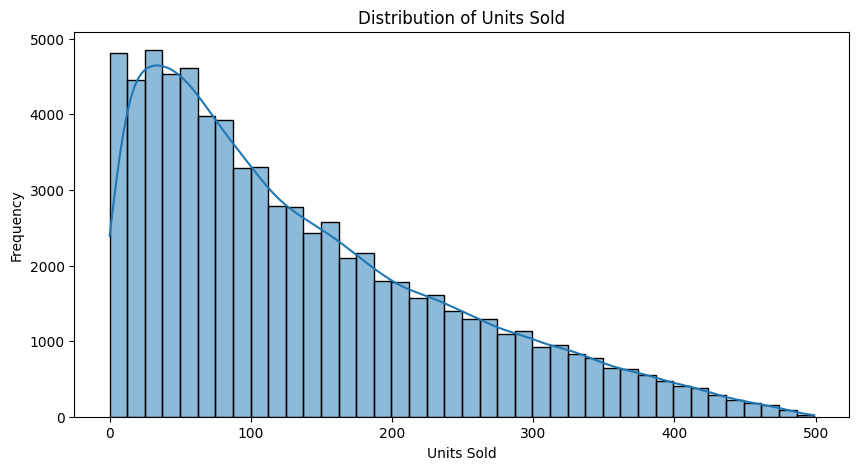

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.histplot(df['Units Sold'], bins=40, kde=True)

plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")

plt.show()

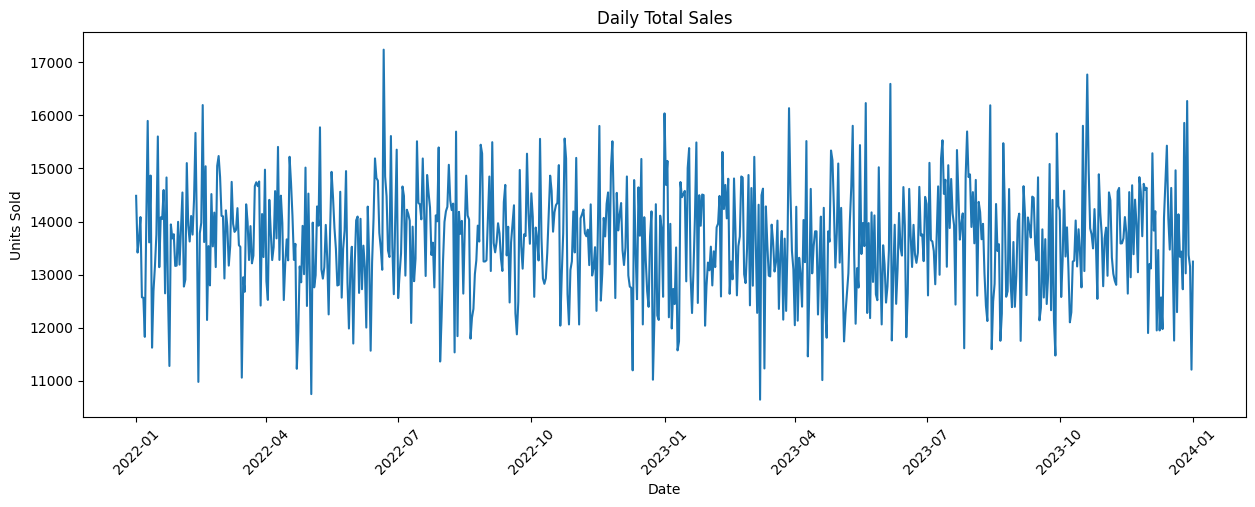

In [10]:
daily_sales = df.groupby('Date')['Units Sold'].sum()

plt.figure(figsize=(15,5))

plt.plot(daily_sales)

plt.title("Daily Total Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.xticks(rotation=45)
plt.show()

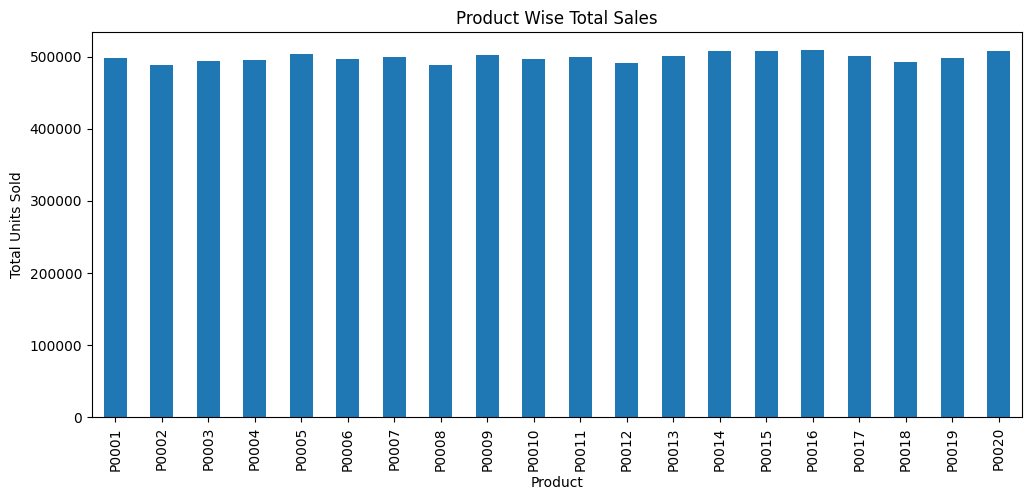

In [11]:
product_sales = df.groupby('Product ID')['Units Sold'].sum()

plt.figure(figsize=(12,5))

product_sales.plot(kind='bar')

plt.title("Product Wise Total Sales")
plt.xlabel("Product")
plt.ylabel("Total Units Sold")

plt.show()

In [12]:
df['Year'] = df['Date'].dt.year

df['Month'] = df['Date'].dt.month

df['Day'] = df['Date'].dt.day

df['DayOfWeek'] = df['Date'].dt.dayofweek

df['DayOfYear'] = df['Date'].dt.dayofyear

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,Year,Month,Day,DayOfWeek,DayOfYear
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,2022,1,1,5,1
1,2022-01-01,S004,P0013,Furniture,East,191,56,65,54.47,61.81,0,Sunny,0,63.92,Autumn,2022,1,1,5,1
2,2022-01-01,S004,P0012,Electronics,North,349,9,165,0.95,14.25,5,Rainy,1,18.56,Spring,2022,1,1,5,1
3,2022-01-01,S004,P0011,Electronics,West,205,46,27,46.65,54.84,0,Sunny,1,57.76,Spring,2022,1,1,5,1
4,2022-01-01,S004,P0010,Groceries,East,447,104,96,115.03,33.48,15,Cloudy,0,37.15,Summer,2022,1,1,5,1


In [13]:
# Target variable
y = df['Units Sold']

# Input features
X = df.drop(columns=[
    'Units Sold',
    'Date',
    'Demand Forecast',
    'Units Ordered'
])

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (73100, 16)
Target shape: (73100,)


In [14]:
# Get unique dates
dates = sorted(df['Date'].unique())

# 80% dates for training
split_index = int(len(dates) * 0.8)

split_date = dates[split_index]

# Chronological split
train_mask = df['Date'] < split_date

X_train = X.loc[train_mask]
X_test = X.loc[~train_mask]

y_train = y.loc[train_mask]
y_test = y.loc[~train_mask]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training ends:", df.loc[train_mask, 'Date'].max())
print("Testing starts:", df.loc[~train_mask, 'Date'].min())

Training data: (58400, 16)
Testing data: (14700, 16)
Training ends: 2023-08-07 00:00:00
Testing starts: 2023-08-08 00:00:00


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=['number']
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_columns),

        ('numerical',
         'passthrough',
         numerical_columns)
    ]
)

print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

Categorical columns: ['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']
Numerical columns: ['Inventory Level', 'Price', 'Discount', 'Holiday/Promotion', 'Competitor Pricing', 'Year', 'Month', 'Day', 'DayOfWeek', 'DayOfYear']


In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Create ML pipeline
model = Pipeline([
    ('preprocessor', preprocessor),

    ('regressor', RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [17]:
# Predict test data
y_pred = model.predict(X_test)

# Display predictions
results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

results.head(10)

,Actual Sales,Predicted Sales
0,123,100.712153
1,33,29.604548
2,241,180.107324
3,100,88.498619
4,59,192.120800
5,90,182.960766
6,51,93.618703
7,153,98.735370
8,28,105.881032
9,103,73.194415


In [18]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

wape = (
    np.abs(y_test.values - y_pred).sum()
    / np.abs(y_test.values).sum()
) * 100

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("WAPE:", round(wape, 2), "%")

MAE: 69.18
RMSE: 88.59
R2 Score: 0.3298
WAPE: 50.91 %


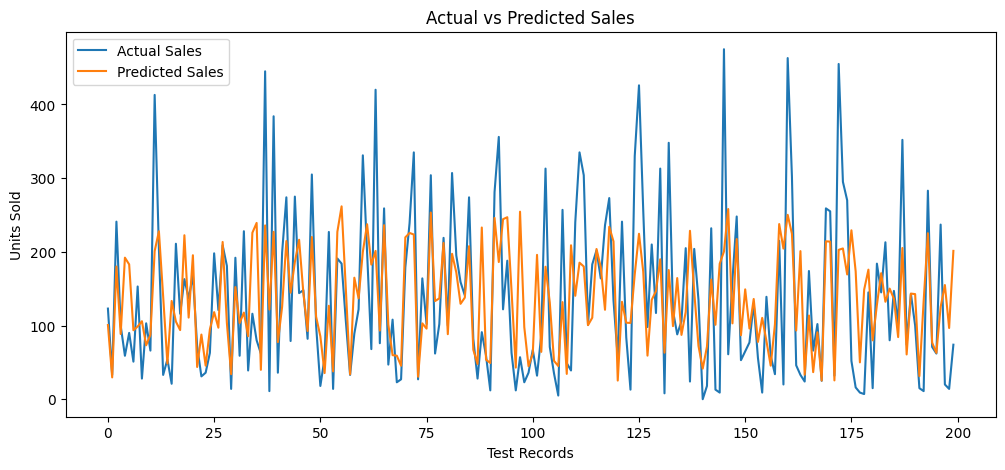

In [19]:
plt.figure(figsize=(12,5))

plt.plot(
    y_test.values[:200],
    label='Actual Sales'
)

plt.plot(
    y_pred[:200],
    label='Predicted Sales'
)

plt.title("Actual vs Predicted Sales")

plt.xlabel("Test Records")
plt.ylabel("Units Sold")

plt.legend()
plt.show()

In [20]:
import joblib

joblib.dump(
    model,
    'inventory_demand_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [21]:
from google.colab import files

files.download('inventory_demand_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

1 Dataset loading

2 Data cleaning and EDA

3 Feature engineering

4 Time-based train/test split

5 Random Forest training

6 Prediction and evaluation

7 Save trained model













